# Kalman Nowcasted Models

We'll also model only work on trying to model EBIT

In [1]:
import os
import sys
import pickle
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from   pykalman import KalmanFilter

In [2]:
note_path  = os.getcwd()
repo_path  = os.path.abspath(os.path.join(note_path, ".."))
data_path  = os.path.join(repo_path, "data")
db_path    = os.path.join(data_path, "DataBase")
quart_path = os.path.join(db_path, "Quarterlyized") 
base_path  = os.path.join(data_path, "Models", "BaselineModels")

In [3]:
path = os.path.join(repo_path, "src")
sys.path.append(path)
from OLSModels import OLSModels

In [4]:
sample_tickers = ['SPX Index', 'RTY Index', 'NDX Index']

path = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")
df_ticker = (pd
    .read_excel(io = path, sheet_name = "FactorGuide")
    .loc[lambda x: x.est_field != "BEST_PE_RATIO"])

real_fields = df_ticker.real_field.drop_duplicates().sort_values().to_list()

In [18]:
path    = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")
RENAMER = (pd
    .read_excel(io = path, sheet_name = "Renamer")
    .loc[lambda x: x.group == "renamer"]
    .set_index("old_name")
    .new_name
    .to_dict())

PLOT_RENAMER = (pd
    .read_excel(io = path, sheet_name = "Renamer")
    .loc[lambda x: x.group == "plot_renamer"]
    .set_index("old_name")
    .new_name
    .to_dict())

FLOAT_FORMAT  = "{:.2f}".format
FLOAT_FORMAT4 = "{:.4f}".format

# Add Nowcasted values to models

In [6]:
path   = os.path.join(base_path, "VolTargetedReturns.parquet")
df_rtn = pd.read_parquet(path = path, engine = "pyarrow")

In [7]:
path = os.path.join(base_path, "KalmanModels.pkl")
with open(path, "rb") as f:
    models = pickle.load(f)

In [8]:
df_kf_list = []

for model_name in list(models.keys()):

    ticker, field, vol, model = model_name.split("-")
    
    model_info  = models[model_name]
    state_means = model_info["state_means"]
    start_date  = model_info["start_date"]
    
    df_add = (df_rtn
        .loc[lambda x: x.ticker == ticker]
        .loc[lambda x: x.vol_target == vol]
        .loc[lambda x: x.date >= start_date]
        .assign(
            y_pred = state_means,
            field  = field))

    df_kf_list.append(df_add)

In [9]:
df_prep = (pd
    .concat(df_kf_list)
    .assign(group_var = lambda x: x.ticker + "-" + x.vol_target + "-" + x.field))

In [10]:
group_vars = df_prep.group_var.drop_duplicates().sort_values().to_list()
models     = {}

for group_var in group_vars: 

    df_tmp = (df_prep
        .loc[lambda x: x.group_var == group_var]
        .set_index("date"))
    
    model = (sm
        .OLS(
            endog = df_tmp.rtn_val,
            exog  = sm.add_constant(df_tmp.y_pred))
        .fit())

    models[group_var] = model

In [11]:
df_params = OLSModels().get_model_params(models)

In [12]:
df_param_prep = (df_params
    .loc[lambda x: x.param_name == "y_pred"]
    .assign(
        ticker     = lambda x: x.name.str.split("-").str[0].str.split(" ").str[0],
        vol_target = lambda x: x.name.str.split("-").str[1],
        field      = lambda x: x.name.str.split("-").str[2]))

The $R^2$ are quite low across the board

In [20]:
display(df_param_prep
    .replace(RENAMER)
    .rename(columns = {
        "ticker"    : "Ticker",
        "vol_target": "",
        "field"     : "Field"})
    .pivot(index = ["Ticker", "Field"], columns = "", values = "r2")
    .rename(columns = {
        "lag_vol_rtn": "Lagged",
        "rtn"        : "None",
        "vol_rtn"    : "Perfect"}))

Lagged          None       Perfect
Ticker Field                                                      
NDX    Cur EV/12M EBITDA  1.767750e-03  1.881366e-03  1.951386e-03
       EBIT               1.046695e-06  5.401408e-07  2.201620e-07
       EV/12M EBITDA      1.449992e-04  2.422753e-04  1.773151e-04
       FCF                4.109481e-05  3.581380e-05  4.848856e-05
       Gross Margin       9.152407e-05  2.147744e-04  1.124082e-04
       IS-EPS             4.218234e-05  5.105111e-05  5.064206e-05
RTY    Cur EV/12M EBITDA  4.944137e-04  5.274867e-04  5.034175e-04
       EBIT               4.270995e-04  5.441840e-05  5.172846e-04
       EV/12M EBITDA      1.815269e-04  2.292261e-04  1.866490e-04
       FCF                7.195924e-04  5.596201e-04  7.654115e-04
       Gross Margin       5.966264e-04  3.289931e-04  5.966644e-04
       IS-EPS             6.689198e-04  5.422103e-04  7.111934e-04
SPX    Cur EV/12M EBITDA  7.744357e-04  7.776212e-04  8.144241e-04
       EBIT               1.587759e-04  2.775676e-05  1.734226e-04
       EV/12M EBITDA      2.118848e-05  2.321437e-05  2.969450e-05
       FCF                5.171528e-05  2.215103e-05  6.234075e-05
       Gross Margin       1.649026e-04  1.833694e-05  1.578236e-04
       IS-EPS             3.150881e-07  5.035821e-07  1.297769e-06

The $\beta$ values don't fare better while the $t$-values are a bit better.

In [22]:
print(df_param_prep
    .drop(columns = ["param_name", "r2", "name"])
    .melt(id_vars = ["ticker", "vol_target", "field"])
    .replace(RENAMER)
    .replace({
        "lag_vol_rtn": "Lagged",
        "rtn"        : "None",
        "vol_rtn"    : "Perfect",
        "pvalue"     : r"$p$-value",
        "tvalue"     : r"$t$-value",
        "param_val"  : "Param. Val"})
    .rename(columns = {
        "ticker"    : "Ticker", 
        "field"     : "Field",
        "variable"  : "",
        "vol_target": "Vol. Target"})
    .pivot(index = ["Ticker", "Field"], columns = ["", "Vol. Target"], values = "value")
    .apply(lambda x: np.round(x,4))
    .to_latex(float_format = FLOAT_FORMAT4))

\begin{tabular}{llrrrrrrrrr}
\toprule
 &  & \multicolumn{3}{r}{Param. Val} & \multicolumn{3}{r}{$p$-value} & \multicolumn{3}{r}{$t$-value} \\
 & Vol. Target & Lagged & None & Perfect & Lagged & None & Perfect & Lagged & None & Perfect \\
Ticker & Field &  &  &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{6}{*}{NDX} & Cur EV/12M EBITDA & 0.0002 & 0.0004 & 0.0002 & 0.0009 & 0.0006 & 0.0005 & 3.3303 & 3.4359 & 3.4993 \\
 & EBIT & -0.0000 & -0.0000 & -0.0000 & 0.9355 & 0.9536 & 0.9704 & -0.0810 & -0.0582 & -0.0371 \\
 & EV/12M EBITDA & 0.0001 & 0.0002 & 0.0001 & 0.3406 & 0.2180 & 0.2920 & 0.9530 & 1.2320 & 1.0539 \\
 & FCF & 0.0000 & 0.0000 & 0.0000 & 0.6119 & 0.6358 & 0.5816 & 0.5073 & 0.4736 & 0.5511 \\
 & Gross Margin & 0.0001 & 0.0004 & 0.0001 & 0.4490 & 0.2461 & 0.4014 & 0.7571 & 1.1599 & 0.8391 \\
 & IS-EPS & 0.0000 & 0.0000 & 0.0000 & 0.6073 & 0.5718 & 0.5733 & 0.5140 & 0.5655 & 0.5632 \\
\cline{1-11}
\multirow[t]{6}{*}{RTY} & Cur EV/12M EBITDA & 0.0000 & 0.0001 & 0.0000 & 0.0502 & 0

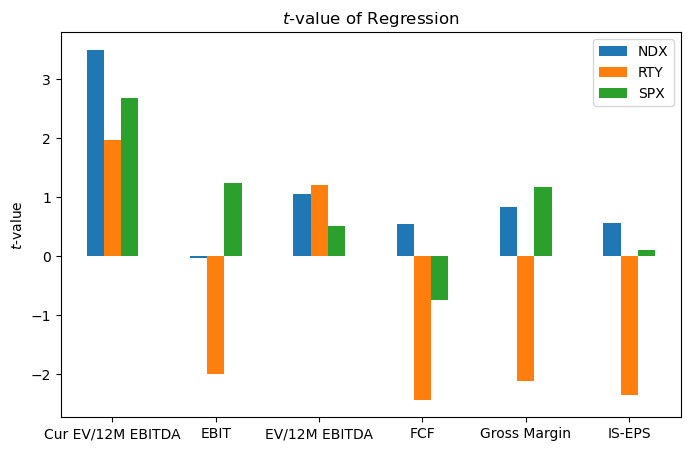

In [15]:
(df_param_prep
    .loc[lambda x: x.vol_target == "vol_rtn"]
    .replace(RENAMER)
    .rename(columns = {"ticker": ""})
    .pivot(index = "field", columns = "", values = "tvalue")
    .plot(
        kind    = "bar",
        figsize = (8,5),
        rot     = 0,
        xlabel  = "",
        ylabel  = r"$t$-value",
        title   = r"$t$-value of Regression"))

plt.show()